In [ ]:
# Creation of Forecast using Nested-EAGLE
# The first half of this notebook is the creation of the Nested-EAGLE forecast. 
# The second half of this notebook is the post-processing of the HRRR forecast data to be completed before verifying with wxvx.

# Step 1: Install Required Packages
%pip install pystac-client obstore obspec-utils geogif xarray "matplotlib<3.10" matplotlib-inline cartopy h5netcdf h5py dask

In [ ]:
#BEGIN Nested-EAGLE forecast creation 

# Step 2: Load Packages
from datetime import datetime, timedelta, timezone

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
import geogif
import matplotlib.pyplot as plt
import numpy as np
import pyproj
import pystac_client
import xarray as xr
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from obspec_utils.readers import BlockStoreReader
from obstore.store import HTTPStore
from pathlib import Path
import math
import pandas as pd

plt.rcParams["figure.figsize"] = (12, 5)

# Define output path
OUTPUT_DIR = Path.cwd()

In [ ]:
# Step 3: Chose forecasts you wish to load
# code will filter stac item search to initializations between start and stop
init_start = "2025-04-01T00:00:00"
init_stop = "2025-04-07T23:00:00"

# chose forecast and the amount of lead time you wish to plot.
init_to_plot = datetime(2025, 4, 1, 00, tzinfo=timezone.utc)
# easy-to-edit lead times
forecast_start_lead = timedelta(hours=0)  # set to 0 to start with initial conditions
forecast_stop_lead = timedelta(hours=240)  # complete forecast horizon

variables_to_load = [
    "2m_temperature",
    "total_precipitation_6hr",
    "meridional_wind",
    "crs",  # required for loading lat/lon info later
]

# Choose desired vertical level: 12 pressure levels from 100 to 1000 hPa
level_to_load = 500

In [7]:
# Step 4: Load STAC items from Planetary Computer.
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    parameters={"sign": "true"},)

matching_items = catalog.search(
    collections=["nested-eagle-conus"],
    datetime=f"{init_start}Z/{init_stop}Z",
).item_collection()

print(len(matching_items))

68


In [8]:
# Step 5: Load a single forecast with obstore and obspec-utils. 
# HTTPStore uses the signed asset URL returned by the STAC API, while BlockStoreReader provides 
# the random-access file interface required by h5netcdf without downloading the entire file.
init_str = init_to_plot.strftime("%Y%m%d-%Hz")
forecast_start = (init_to_plot + forecast_start_lead).strftime("%Y-%m-%dT%H:%M:%S")
forecast_stop = (init_to_plot + forecast_stop_lead).strftime("%Y-%m-%dT%H:%M:%S")

item = next(
    (entry for entry in matching_items if entry.id.endswith(init_str)),
    None,)

asset_href = item.assets["conus"].href
store = HTTPStore.from_url(asset_href)

with BlockStoreReader(store, "") as remote_file, xr.open_dataset(
    remote_file,
    engine="h5netcdf",
    chunks={},
) as full_ds:
    ds = (
        full_ds[variables_to_load]
        .sel(
            time=slice(forecast_start, forecast_stop),
            level=level_to_load,
        )
        .load())

In [9]:
# Step 6: Create lat/lon coordinates for the curvilinear grid

# build 2D x/y grid
xx, yy = np.meshgrid(ds["x"].values, ds["y"].values)

# source CRS from the WKT string in the dataset
src_crs = pyproj.CRS.from_wkt(ds["crs"].attrs["spatial_ref"])

# target CRS: lon/lat
dst_crs = pyproj.CRS.from_epsg(4326)

transformer = pyproj.Transformer.from_crs(
    src_crs,
    dst_crs,
    always_xy=True,
)

lon, lat = transformer.transform(xx, yy)

# add lon/lat as 2D coordinates
ds = ds.assign_coords(
    lon=(("y", "x"), lon),
    lat=(("y", "x"), lat),
)

ds

<xarray.Dataset> Size: 207MB
Dimensions:                  (time: 41, y: 480, x: 848)
Coordinates:
  * time                     (time) datetime64[ns] 328B 2025-04-01 ... 2025-0...
  * y                        (y) float64 4kB -1.436e+06 -1.43e+06 ... 1.438e+06
  * x                        (x) float64 7kB -2.546e+06 -2.54e+06 ... 2.536e+06
    lon                      (y, x) float64 3MB -121.7 -121.7 ... -63.68 -63.6
    lat                      (y, x) float64 3MB 22.75 22.76 ... 47.17 47.15
    level                    int64 8B 500
Data variables:
    2m_temperature           (time, y, x) float32 67MB 291.5 291.5 ... 273.9
    total_precipitation_6hr  (time, y, x) float32 67MB nan nan nan ... 0.0 0.0
    meridional_wind          (time, y, x) float32 67MB -2.191 -2.236 ... 5.616
    crs                      int64 8B 0
Attributes:
    forecast_reference_time:  2025-04-01T00:00:00.000000000
    description:              Output from NOAA's Nested-EAGLE forecast model ...
    grid_projection:          Lambert Conic Conformal (LCC)
    horizontal_resolution:    6km
    version:                  1.0
    Conventions:              CF-1.8

In [10]:
# Step 7: Make the Nested-EAGLE dataset compatible with wxvx for 2 m temperature
# Remove the unrelated scalar 500 hPa coordinate
if "level" in ds.coords:
    ds = ds.drop_vars("level")

# Use the coordinate names expected by the wxvx config
for key in ["x", "y"]:
    if key in ds.coords:
        ds = ds.drop_vars(key)

ds = ds.rename({"x": "longitude", "y": "latitude"})

ds = ds.rename({"lon": "longitude", "lat": "latitude"})

# Add a real singleton height dimension to 2 m temperature
t2m = ds["2m_temperature"].expand_dims(
    heightAboveGround=[2],
    axis=1,
)

t2m["heightAboveGround"].attrs = {
    "long_name": "Height Above Ground",
    "standard_name": "height",
    "units": "m",
    "positive": "up",
    "axis": "Z",
}

# This is the file you will load into wxvx
OUTPUT_FILE = "nested_eagle.zarr"
OUTPUT_PATH = OUTPUT_DIR / OUTPUT_FILE
ds.to_zarr(str(OUTPUT_PATH), mode="w")
print(ds)

<xarray.Dataset> Size: 207MB
Dimensions:                  (time: 41, latitude: 480, longitude: 848)
Coordinates:
  * time                     (time) datetime64[ns] 328B 2025-04-01 ... 2025-0...
    latitude                 (latitude, longitude) float64 3MB 22.75 ... 47.15
    longitude                (latitude, longitude) float64 3MB -121.7 ... -63.6
Data variables:
    2m_temperature           (time, latitude, longitude) float32 67MB 291.5 ....
    total_precipitation_6hr  (time, latitude, longitude) float32 67MB nan ......
    meridional_wind          (time, latitude, longitude) float32 67MB -2.191 ...
    crs                      int64 8B 0
Attributes:
    forecast_reference_time:  2025-04-01T00:00:00.000000000
    description:              Output from NOAA's Nested-EAGLE forecast model ...
    grid_projection:          Lambert Conic Conformal (LCC)
    horizontal_resolution:    6km
    version:                  1.0
    Conventions:              CF-1.8


c:\Users\639498\Desktop\NOAA\scripts\.venv\Lib\site-packages\zarr\api\asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


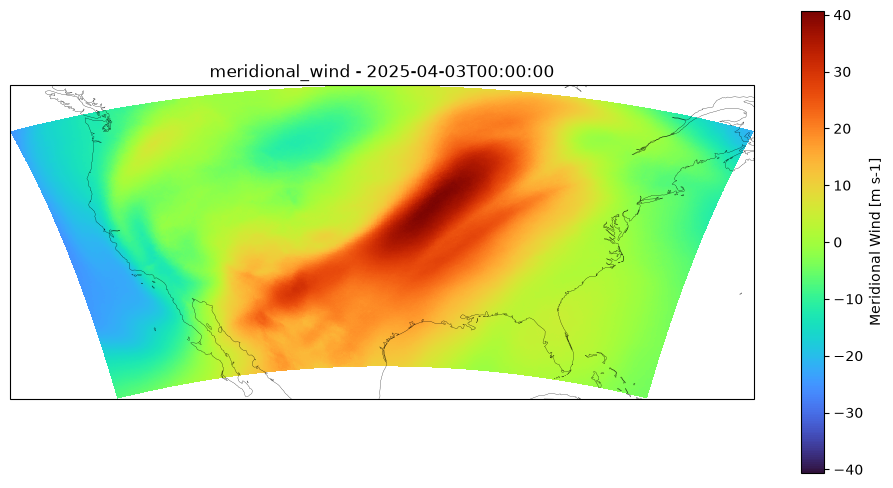

In [11]:
# Step 8: Begin test plots
#  plot surface variable
var_to_plot = "meridional_wind"  # can change to meridional wind or precipitation.
time_to_plot = "2025-04-03T00:00:00"  # can change to a different hour in your forecast.

field = (
    ds[var_to_plot]
    .sel(
        time=time_to_plot,
    )
    .squeeze())

fig, ax = plt.subplots(
    figsize=(12, 6),
    subplot_kw={"projection": ccrs.PlateCarree()},)

field.plot.pcolormesh(
    ax=ax, x="longitude", y="latitude", transform=ccrs.PlateCarree(), cmap="turbo")

plt.title(f"{var_to_plot} - {time_to_plot}")

ax.coastlines(linewidth=0.2)
plt.show()

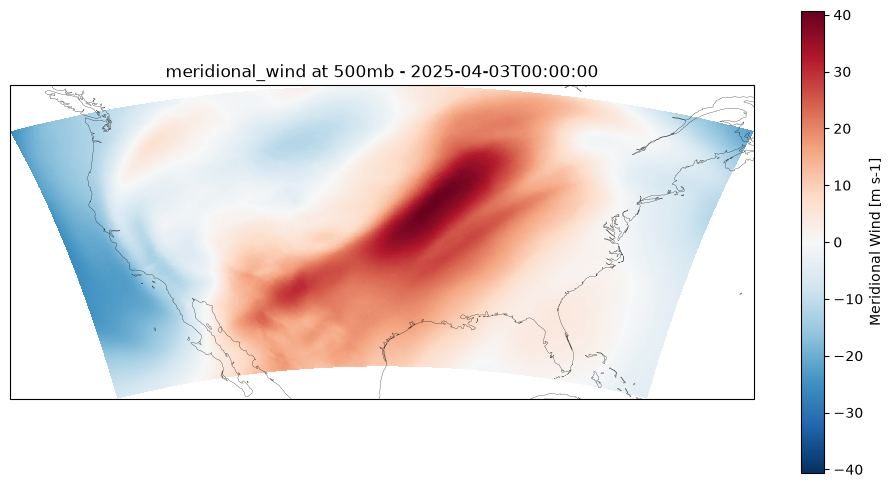

In [12]:
#plot pressure level
var_to_plot = "meridional_wind"  # can change to meridional wind or precipitation.
time_to_plot = "2025-04-03T00:00:00"  # can change to a different hour in your forecast.

field = (
    ds[var_to_plot]
    .sel(
        time=time_to_plot,
    )
    .squeeze())

fig, ax = plt.subplots(
    figsize=(12, 6),
    subplot_kw={"projection": ccrs.PlateCarree()},)

field.plot.pcolormesh(
    ax=ax, x="longitude", y="latitude", transform=ccrs.PlateCarree(), cmap="RdBu_r")

plt.title(f"{var_to_plot} at {level_to_load}mb - {time_to_plot}")

ax.coastlines(linewidth=0.2)
plt.show()

In [ ]:
# plot precipitation animation 
import cartopy.feature as cfeature

var_to_plot = "total_precipitation_6hr"

field = ds[var_to_plot]
gif_title = f"nested-EAGLE CONUS forecast initialized {init_to_plot:%Y-%m-%d %HZ}"
scale_label = f"{field.attrs['long_name']} ({field.attrs['units']})"


def add_progress_bar(image, frame_index, frame_count):
    height, width, _ = image.shape
    margin = max(8, width // 50)
    bar_height = max(6, height // 60)
    y_start = height - margin - bar_height
    x_start, x_stop = margin, width - margin
    fill_stop = x_start + round((x_stop - x_start) * (frame_index + 1) / frame_count)
    bar_rows = slice(y_start, y_start + bar_height)
    image[bar_rows, slice(x_start, x_stop)] = (30, 30, 30)
    image[bar_rows, slice(x_start, fill_stop)] = (255, 255, 255)
    return image


countries = shpreader.Reader(
    shpreader.natural_earth(
        resolution="50m",
        category="cultural",
        name="admin_0_countries",
    )
)
united_states = next(
    record.geometry
    for record in countries.records()
    if record.attributes["ADMIN"] == "United States of America")

frames = []
for frame_index, frame in enumerate(field):
    fig = Figure(figsize=(10, 6), dpi=100)
    FigureCanvasAgg(fig)
    ax = fig.add_subplot(projection=ccrs.PlateCarree())
    mesh = ax.pcolormesh(
        ds.longitude,
        ds.latitude,
        frame,
        transform=ccrs.PlateCarree(),
        shading="auto",
        cmap="gist_ncar_r",
        vmin=0,
        vmax=30,
    )
    ax.set_title(gif_title, fontsize=14)
    colorbar = fig.colorbar(
        mesh,
        ax=ax,
        orientation="horizontal",
        pad=0.03,
        shrink=0.75,
    )
    colorbar.set_label(scale_label)
    ax.add_geometries(
        [united_states],
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="black",
        linewidth=1,
    ) 
    ax.add_feature(cfeature.STATES, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=1.0)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)


    ax.set_extent(
        [
            float(ds.longitude.min()),
            float(ds.longitude.max()),
            float(ds.latitude.min()),
            float(ds.latitude.max()),
        ],
        crs=ccrs.PlateCarree(),
    )
    ax.set_axis_off()
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.08, top=0.92)
    fig.canvas.draw()
    image = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
    frames.append(add_progress_bar(image, frame_index, field.sizes["time"]))

rgb_frames = xr.DataArray(
    np.stack(frames).transpose(0, 3, 1, 2),
    dims=("time", "band", "y", "x"),
    coords={"time": field.time, "band": ["red", "green", "blue"]},
).chunk({"time": 1})

geogif.dgif(
    rgb_frames,
    fps=2,
    date_format="%Y-%m-%dT%H:%M UTC",
).compute()

gif = geogif.dgif(
    rgb_frames,
    fps=2,  # choose playback speed- 4 is max, faster
    date_format="%Y-%m-%dT%H:%M UTC",
).compute()

OUTPUT_GIF = "total_precipitation_forecast.gif"
OUTPUT_PATH = OUTPUT_DIR / OUTPUT_GIF

with open(OUTPUT_PATH, "wb") as f:
    f.write(gif.data)

print(f"Saved: {OUTPUT_PATH}")

# END Nested-EAGLE forecast creation

Saved: c:\Users\639498\Desktop\NOAA\scripts\total_precipitation_forecast1.gif


In [ ]:
# BEGIN HRRR POST-PROCESSING 

# Step 1: get 6hourly accumulated precip
# needs to be completed for both the hrrr_april.zarr (first 24 hrs) and hrrr_april_middle.zarr (60-108 hrs)

zarr_path = Path.cwd() / "hrrr_april.zarr"

# Open the existing Zarr store.
ds = xr.open_zarr(zarr_path)

if "accum_tp" not in ds:
    raise KeyError("The Zarr store does not contain 'accum_tp'.")

if "fhr" not in ds["accum_tp"].dims:
    raise ValueError("'accum_tp' does not have an 'fhr' dimension.")

fhr = np.asarray(ds["fhr"].values)

# This method assumes F06, F12, F18, F24, etc.
if len(fhr) == 0 or fhr[0] != 6:
    raise ValueError(
        f"Expected the first forecast hour to be 6, but found {fhr[0]}."
    )

if len(fhr) > 1 and not np.all(np.diff(fhr) == 6):
    raise ValueError(
        f"Forecast hours must be spaced every 6 hours. Found: {fhr}"
    )

cumulative = ds["accum_tp"]

# F06 is already the total for hours 0–6.
first_interval = cumulative.isel(fhr=slice(0, 1))

# Later intervals are differences between consecutive cumulative totals:
# F12-F06, F18-F12, F24-F18, etc.
later_intervals = cumulative.diff("fhr", label="upper")

precip_6h = xr.concat(
    [first_interval, later_intervals],
    dim="fhr",
)

# Remove tiny negative values caused by numerical precision.
precip_6h = precip_6h.clip(min=0)

# Preserve the original metadata, but describe the transformed field.
precip_6h.attrs = cumulative.attrs.copy()
precip_6h.attrs.update(
    {
        "long_name": "Total precipitation accumulated over previous 6 hours",
        "accumulation_hours": 6,
        "postprocessing": (
            "First forecast value retained; subsequent values calculated "
            "by differencing consecutive cumulative forecast accumulations."
        ),
    }
)

# Save a copy of the original cumulative precipitation in the same store.
print("Saving original data as 'accum_tp_cumulative'...")

cumulative_backup = cumulative.rename("accum_tp_cumulative")
cumulative_backup.attrs = cumulative.attrs.copy()
cumulative_backup.attrs["long_name"] = (
    "Total precipitation accumulated since forecast initialization"
)

cumulative_backup.to_dataset().drop_vars(
    ["valid_time", "lead_time"],
    errors="ignore",
).to_zarr(
    zarr_path,
    mode="a",
)

# Replace accum_tp with the calculated 6-hour interval totals.
print("Replacing 'accum_tp' with 6-hour precipitation totals...")


precip_6h.rename("accum_tp").to_dataset().drop_vars(
    ["valid_time", "lead_time"],
    errors="ignore",
).to_zarr(
    zarr_path,
    mode="a",
)

# Reopen and verify.
updated = xr.open_zarr(zarr_path)

print("\nFinished.")
print("Forecast hours:", updated["fhr"].values)
print(updated["accum_tp"])
print("\nOriginal cumulative field:")
print(updated["accum_tp_cumulative"])

In [ ]:
# check precip 6hourly accum worked (optional, change y and x coordinates as needed)
print(ds["accum_tp"].isel(t0=0, y=205, x=226).values)

In [ ]:
# Step 2 (required)
# correct dimensions and structure for wxvx 
src = "hrrr_april.zarr"
dst = "hrrr_april_wxvx.zarr"

ds = xr.open_zarr(src)

time_values = (
    ds["time"].values[0]
    + ds["fhr"].values.astype("timedelta64[h]")
).astype("datetime64[ns]")

lat_values = ds["latitude"].values
lon_values = ds["longitude"].values

ny, nx = lat_values.shape

data_vars = {}

for var_name, var in ds.data_vars.items():

    if set(var.dims) != {"time", "fhr", "y", "x"}:
        continue

    print("Adding:", var_name)

    new_var = xr.DataArray(
        var.isel(time=0, drop=True).data,
        dims=("time", "latitude", "longitude"),
        coords={
            "time": ("time", time_values),
        },
        name=var_name,
        attrs=dict(var.attrs),
    )

    new_var.attrs.pop("coordinates", None)

    data_vars[var_name] = new_var

print("\nVariables being written:")
print(list(data_vars.keys()))

out = xr.Dataset(
    data_vars=data_vars,
    coords={
        "time": ("time", time_values),
        "latitude": (
            ("latitude", "longitude"),
            lat_values,
        ),
        "longitude": (
            ("latitude", "longitude"),
            lon_values,
        ),
    },
    attrs=dict(ds.attrs),
)

out["time"].attrs = {
    "axis": "T",
    "standard_name": "time",
    "long_name": "valid time",
}

out["latitude"].attrs = {
    "standard_name": "latitude",
    "units": "degrees_north",
}

out["longitude"].attrs = {
    "standard_name": "longitude",
    "units": "degrees_east",
}

out.attrs["forecast_reference_time"] = str(
    ds["t0"].values[0]
)

out.attrs["Conventions"] = "CF-1.8"

for var in out.variables:
    out[var].encoding = {}

encoding = {}

for var_name in out.data_vars:
    encoding[var_name] = {
        "chunks": (1, ny, nx)
    }

encoding["latitude"] = {"chunks": (ny, nx)}
encoding["longitude"] = {"chunks": (ny, nx)}

print("\nVariables before writing:")
print(list(out.data_vars))

out.to_zarr(
    dst,
    mode="w",
    consolidated=True,
    zarr_format=2,
    encoding=encoding,
)

recheck = xr.open_zarr(dst)

print("\nVariables after writing:")
print(list(recheck.data_vars))

print("\nDataset structure:")
print(check)

print("\nVariables:")
print(list(check.data_vars))

print("\nDimensions:")
print(dict(check.sizes))

print("\nTime values:")
print(check["time"].values)

print("\nContains NaT?")
print(np.isnat(check["time"].values).any())

print("\nVariable dimensions:")
for var in check.data_vars:
    print(f"{var}: {check[var].dims}")

In [ ]:
#optional double check of variables
check = xr.open_zarr("hrrr_april_wxvx.zarr")

print("\nDataset structure:")
print(check)

print("\nVariables:")
print(list(check.data_vars))

print("\nDimensions:")
print(dict(check.sizes))

print("\nTime values:")
print(check["time"].values)

print("\nContains NaT?")
print(np.isnat(check["time"].values).any())

print("\nVariable dimensions:")
for var in check.data_vars:
    print(f"{var}: {check[var].dims}")

In [ ]:
# Step 3: visualize

ds = xr.open_zarr("hrrr_april_wxvx.zarr")

var_to_plot = "accum_tp"

field = ds[var_to_plot]

init_time = np.datetime64(
    ds.attrs["forecast_reference_time"]
)

gif_title = (
    f"HRRR forecast initialized "
    f"{np.datetime_as_string(init_time, unit='h')} UTC"
)

scale_label = (
    f"{field.attrs.get('long_name', var_to_plot)} "
    f"({field.attrs.get('units', '')})"
)

valid_times = ds.time.values

print(valid_times)


def add_progress_bar(image, frame_index, frame_count):

    height, width, _ = image.shape

    margin = max(8, width // 50)
    bar_height = max(6, height // 60)

    y_start = height - margin - bar_height

    x_start = margin
    x_stop = width - margin

    fill_stop = x_start + round(
        (x_stop - x_start)
        * (frame_index + 1)
        / frame_count
    )

    image[
        y_start:y_start + bar_height,
        x_start:x_stop,
    ] = (30, 30, 30)

    image[
        y_start:y_start + bar_height,
        x_start:fill_stop,
    ] = (255, 255, 255)

    return image


countries = shpreader.Reader(
    shpreader.natural_earth(
        resolution="50m",
        category="cultural",
        name="admin_0_countries",
    )
)

united_states = next(
    record.geometry
    for record in countries.records()
    if record.attributes["ADMIN"]
    == "United States of America"
)

frames = []

for frame_index in range(field.sizes["time"]):

    frame = field.isel(
        time=frame_index
    )

    valid_time = valid_times[frame_index]

    fig = Figure(figsize=(10, 6), dpi=100)
    FigureCanvasAgg(fig)

    ax = fig.add_subplot(
        projection=ccrs.PlateCarree()
    )

    mesh = ax.pcolormesh(
        ds.longitude,
        ds.latitude,
        frame,
        transform=ccrs.PlateCarree(),
        shading="auto",
        cmap="gist_ncar_r",
        vmin=0,
        vmax=30,
    )

    ax.set_title(
        gif_title
        + "\n"
        + f"Valid: {np.datetime_as_string(valid_time, unit='h')} UTC",
        fontsize=14,
    )

    colorbar = fig.colorbar(
        mesh,
        ax=ax,
        orientation="horizontal",
        pad=0.03,
        shrink=0.75,
    )

    colorbar.set_label(scale_label)

    ax.add_geometries(
        [united_states],
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="black",
        linewidth=1,
    )

    ax.add_feature(
        cfeature.STATES,
        linewidth=0.5,
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=1.0,
    )

    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.8,
    )

    ax.set_extent(
        [
            float(ds.longitude.min()),
            float(ds.longitude.max()),
            float(ds.latitude.min()),
            float(ds.latitude.max()),
        ],
        crs=ccrs.PlateCarree(),
    )

    ax.set_axis_off()

    fig.subplots_adjust(
        left=0.02,
        right=0.98,
        bottom=0.08,
        top=0.92,
    )

    fig.canvas.draw()

    image = np.asarray(
        fig.canvas.buffer_rgba()
    )[..., :3].copy()

    frames.append(
        add_progress_bar(
            image,
            frame_index,
            field.sizes["time"],
        )
    )

rgb_frames = xr.DataArray(
    np.stack(frames).transpose(0, 3, 1, 2),
    dims=("time", "band", "y", "x"),
    coords={
        "time": field.time,
        "band": ["red", "green", "blue"],
    },
).chunk({"time": 1})

gif = geogif.dgif(
    rgb_frames,
    fps=2,
    date_format="%Y-%m-%d %H UTC",
).compute()

OUTPUT_PATH = Path(
    "hrrr_6hr_precip_forecast.gif"
)

with open(OUTPUT_PATH, "wb") as f:
    f.write(gif.data)

print(f"Saved: {OUTPUT_PATH}")